<a href="https://colab.research.google.com/github/fauzia-annisa/customer-review-sentiment-classifier/blob/main/customer_review_sentiment_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing the Dependencies

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re, glob, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

Data Collection & Processing

In [9]:
# loading the data from tsv file to a Pandas DataFrame
reviews = pd.read_csv('/content/amazon_alexa.tsv', sep='\t')

In [10]:
# print the first 5 rows of the dataframe
reviews.head()

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1


In [11]:
# checking the number of rows and columns
reviews.shape

(3150, 5)

In [12]:
# getting some information about the data
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   rating            3150 non-null   int64 
 1   date              3150 non-null   object
 2   variation         3150 non-null   object
 3   verified_reviews  3149 non-null   object
 4   feedback          3150 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 123.2+ KB


In [13]:
# checking for missing values
reviews.isnull().sum()

,0
rating,0
date,0
variation,0
verified_reviews,1
feedback,0


Data Analysis

In [14]:
# counting positive (1) and negative (0) reviews
reviews['feedback'].value_counts()

,count
feedback,
1,2893
0,257


In [15]:
# get some statistical measures about the star ratings
reviews['rating'].describe()

,rating
count,3150.000000
mean,4.463175
std,1.068506
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


Data Visualization

In [16]:
sns.set_theme(style="whitegrid")

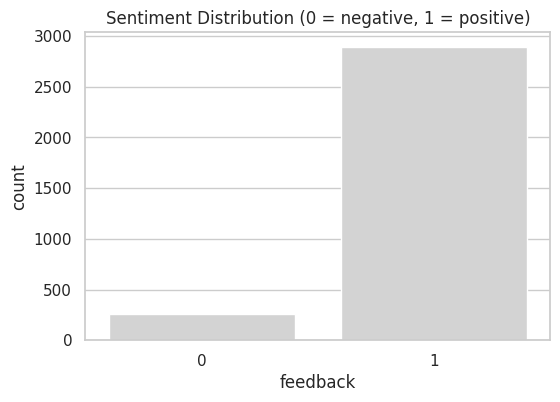

In [17]:
# plotting the sentiment counts
plt.figure(figsize=(6,4))
sns.countplot(x=reviews['feedback'], color='lightgrey')
plt.title('Sentiment Distribution (0 = negative, 1 = positive)')
plt.show()

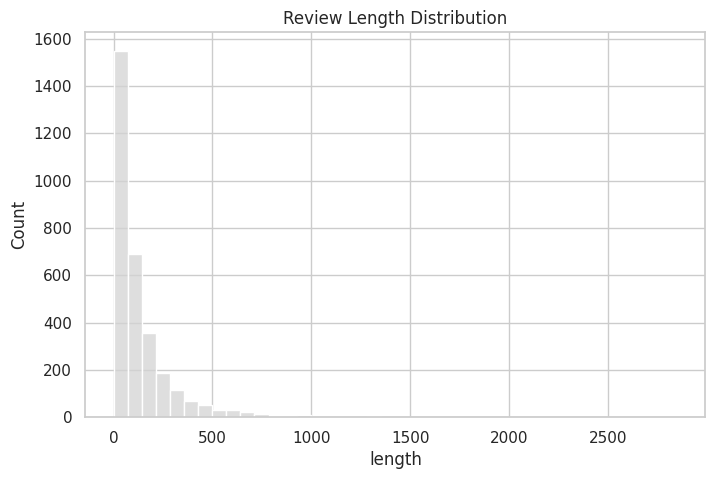

In [18]:
# finding the distribution of review length
reviews['length'] = reviews['verified_reviews'].fillna('').str.len()
plt.figure(figsize=(8,5))
sns.histplot(reviews['length'], bins=40, color='lightgrey')
plt.title('Review Length Distribution')
plt.show()

In [19]:
# average review length for each sentiment
reviews.groupby('feedback')['length'].mean()

,length
feedback,
0,215.225681
1,124.659177


Cleaning the Text Data

In [20]:
# keeping only the review text and the label
data = reviews[['verified_reviews', 'feedback']].copy()
data.columns = ['text', 'sentiment']

In [21]:
# removing empty reviews and duplicates
data['text'] = data['text'].fillna('').astype(str)
data = data[data['text'].str.strip() != '']
data = data.drop_duplicates()
data.shape

(2299, 2)

In [22]:
# function to clean the text
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

In [23]:
# applying the function to every review
data['clean_text'] = data['text'].apply(clean_text)
data = data[data['clean_text'] != '']
data[['text', 'clean_text']].head()

,text,clean_text
0,Love my Echo!,love my echo
1,Loved it!,loved it
2,"Sometimes while playing a game, you can answer...",sometimes while playing a game you can answer ...
3,I have had a lot of fun with this thing. My 4 ...,i have had a lot of fun with this thing my yr ...
4,Music,music


In [24]:
# checking the sentiment counts after cleaning
data['sentiment'].value_counts()

,count
sentiment,
1,2090
0,205


In [25]:
X = data['clean_text']
Y = data['sentiment']

Splitting the data into training data and Test data

In [26]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2, stratify=Y)

In [27]:
print(X.shape, X_train.shape, X_test.shape)

(2295,) (1836,) (459,)


Converting the text data to numerical values (TF-IDF)

In [28]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [29]:
print(X_train_tfidf.shape, X_test_tfidf.shape)

(1836, 7047) (459, 7047)


Model Training (Logistic Regression)

In [30]:
# loading the model
model = LogisticRegression(max_iter=1000, class_weight='balanced')

In [31]:
# training the model with X_train
model.fit(X_train_tfidf, Y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

Evaluation (Prediction on Test Data)

In [32]:
test_data_prediction = model.predict(X_test_tfidf)

In [33]:
print(test_data_prediction[:20])

[1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1]


Accuracy, Precision, Recall, F1-Score

In [34]:
print("Accuracy :", round(metrics.accuracy_score(Y_test, test_data_prediction), 3))
print("Precision:", round(metrics.precision_score(Y_test, test_data_prediction), 3))
print("Recall   :", round(metrics.recall_score(Y_test, test_data_prediction), 3))
print("F1-Score :", round(metrics.f1_score(Y_test, test_data_prediction), 3))

Accuracy : 0.878
Precision: 0.959
Recall   : 0.904
F1-Score : 0.931


In [35]:
# detailed report for each class
print(classification_report(Y_test, test_data_prediction, target_names=['Negative', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.38      0.61      0.47        41
    Positive       0.96      0.90      0.93       418

    accuracy                           0.88       459
   macro avg       0.67      0.76      0.70       459
weighted avg       0.91      0.88      0.89       459



Confusion Matrix

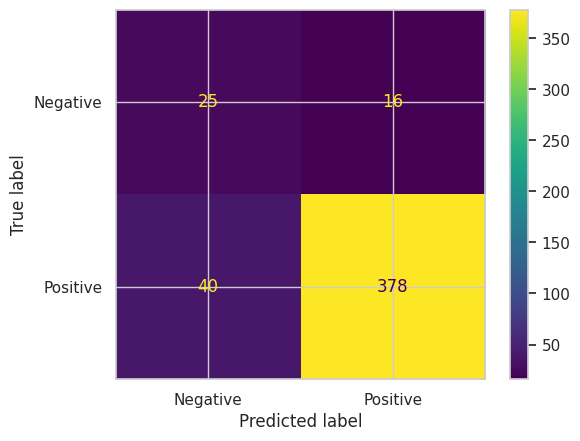

In [36]:
cm = metrics.confusion_matrix(Y_test, test_data_prediction)
ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive']).plot()
plt.savefig('confusion_matrix.png')
plt.show()

Saving the Model and Preprocessing Components

In [37]:
joblib.dump(model, 'sentiment_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')
print("Saved")

Saved


# New Section

In [38]:
import joblib

model = joblib.load('sentiment_model.pkl')
tfidf = joblib.load('tfidf_vectorizer.pkl')

def predict_sentiment(text):
    vec = tfidf.transform([text])
    pred = model.predict(vec)[0]
    return "Positive" if pred == 1 else "Negative"

In [39]:
print(predict_sentiment("Love it, works great"))
print(predict_sentiment("Stopped working, waste of money"))
print(predict_sentiment("Not good at all"))

Positive
Negative
Negative


README and requirements.txt

In [40]:
acc = round(metrics.accuracy_score(Y_test, test_data_prediction), 3)
lines = [
"# Customer Review Sentiment Classifier",
"",
"Classifies customer reviews as Positive or Negative (TF-IDF + Logistic Regression).",
"",
"## Data",
"Amazon Alexa Reviews (Kaggle, user sid321axn), about 3,150 labeled reviews.",
"Columns used: verified_reviews (text) and feedback (1 = positive, 0 = negative).",
"Empty reviews and duplicates were removed before training.",
"",
"## Setup",
"pip install -r requirements.txt",
"",
"## Files",
"- sentiment_model.pkl: trained model",
"- tfidf_vectorizer.pkl: fitted text vectorizer",
"- confusion_matrix.png: evaluation chart",
"",
"## Results (held-out 20% test set)",
"Accuracy: " + str(acc),
"",
"## Usage",
"Load both .pkl files with joblib, clean the text,",
"transform it with the vectorizer, then call model.predict().",
]
open('README.md', 'w').write("\n".join(lines))
open('requirements.txt', 'w').write("pandas\nscikit-learn\njoblib\nmatplotlib\nseaborn\n")
print("README.md and requirements.txt created")

README.md and requirements.txt created
